# Analyzing Time Series Data with Socrata and Python

In [120]:
import os
os.getcwd()


'c:\\Users\\samvi\\TE_440'

## Loading datasets into our notebook

We'll start by loading a city of Chicago permits dataset into a Pandas DataFrame. We'll use the open source sodapy Python Socrata module to do this.

In [121]:
import pandas as pd
from sodapy import Socrata

# load Chicago permits data
chicago_permits_df = pd.read_csv(r'Building_Permits_20261024.csv')

C:\Users\samvi\AppData\Local\Temp\ipykernel_66692\3051175401.py:5: DtypeWarning: Columns (0: ID, 1: PERMIT#, 2: PROCESSING_TIME, 3: WORK_TYPE, 4: PERMIT_CONDITION, 5: CONTACT_1_ZIPCODE, 6: CONTACT_2_ZIPCODE, 7: CONTACT_3_ZIPCODE, 8: CONTACT_4_ZIPCODE, 9: CONTACT_5_ZIPCODE, 10: CONTACT_6_TYPE, 11: CONTACT_6_NAME, 12: CONTACT_6_CITY, 13: CONTACT_6_STATE, 14: CONTACT_6_ZIPCODE, 15: CONTACT_7_TYPE, 16: CONTACT_7_NAME, 17: CONTACT_7_CITY, 18: CONTACT_7_STATE, 19: CONTACT_7_ZIPCODE, 20: CONTACT_8_TYPE, 21: CONTACT_8_NAME, 22: CONTACT_8_CITY, 23: CONTACT_8_STATE, 24: CONTACT_8_ZIPCODE, 25: CONTACT_9_TYPE, 26: CONTACT_9_NAME, 27: CONTACT_9_CITY, 28: CONTACT_9_STATE, 29: CONTACT_9_ZIPCODE, 30: CONTACT_10_TYPE, 31: CONTACT_10_NAME, 32: CONTACT_10_CITY, 33: CONTACT_10_STATE, 34: CONTACT_10_ZIPCODE, 35: CONTACT_11_TYPE, 36: CONTACT_11_NAME, 37: CONTACT_11_CITY, 38: CONTACT_11_STATE, 39: CONTACT_11_ZIPCODE, 40: CONTACT_12_TYPE, 41: CONTACT_12_NAME, 42: CONTACT_12_CITY, 43: CONTACT_12_STATE, 44: CON

In the next few cells we'll do some exploration of our datasets using the `len`, `head`, and `value_counts` functions. We'll start by getting a sense of how many rows are in each of our datasets with the `len` function.

Now let's see have a peek at the first 10 rows in each of those dataset using the `head` method. You can optionally pass a parameter for the number of rows you want to print if 5 isn't enough.

In [122]:
print(len(chicago_permits_df))
chicago_permits_df.head(10)

851305


,ID,PERMIT#,PERMIT_STATUS,PERMIT_MILESTONE,PERMIT_TYPE,REVIEW_TYPE,APPLICATION_START_DATE,ISSUE_DATE,PROCESSING_TIME,STREET_NUMBER,...,REPORTED_COST,PIN_LIST,COMMUNITY_AREA,CENSUS_TRACT,WARD,XCOORDINATE,YCOORDINATE,LATITUDE,LONGITUDE,LOCATION
0,3368573,101046020,NaN,NaN,PERMIT - SIGNS,SIGN PERMIT,03/08/2024,09/18/2024,194,7529.0,...,"$5,500.00",NaN,1.0,10202.0,49.0,1.162912e+06,1.950065e+06,42.018631,-87.675845,POINT (-87.675844598018 42.018631130261)
1,3423504,101072844,ACTIVE,INSPECTIONS,PERMIT - RENOVATION/ALTERATION,SELF CERT,08/08/2025,10/14/2025,67,2219.0,...,"$20,000.00",1730102015,31.0,841300.0,25.0,1.161422e+06,1.889146e+06,41.851494,-87.683028,POINT (-87.683027767753 41.851494345646)
2,2486241,100498645,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,07/08/2013,07/08/2013,0,2648.0,...,"$24,815.00",1429408053,7.0,70400.0,32.0,1.168462e+06,1.917958e+06,41.930408,-87.656354,POINT (-87.656354338933 41.930408052126)
3,2487337,100499294,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,07/11/2013,07/11/2013,0,9426.0,...,"$7,800.00",2503429023,49.0,490400.0,9.0,1.181524e+06,1.842462e+06,41.722950,-87.610690,POINT (-87.610689567581 41.722949542022)
4,2490603,100500984,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,07/23/2013,07/23/2013,0,2236.0,...,"$9,950.00",1418102025,4.0,40600.0,47.0,1.160442e+06,1.931543e+06,41.967856,-87.685451,POINT (-87.685451345211 41.9678557176)
5,2502999,100508118,EXPIRED,INSPECTIONS,PERMIT - RENOVATION/ALTERATION,STANDARD PLAN REVIEW,09/27/2013,09/27/2013,0,3140.0,...,"$5,000.00",1325108007,21.0,210700.0,33.0,1.156123e+06,1.920774e+06,41.938394,-87.701623,POINT (-87.701622534072 41.938394321835)
6,2505730,100509770,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,09/20/2013,09/20/2013,0,1842.0,...,"$15,000.00",1336311029,22.0,222600.0,35.0,1.156038e+06,1.912280e+06,41.915089,-87.702166,POINT (-87.702165580572 41.915088795478)
7,2512402,100513804,COMPLETE,COMPLETE,PERMIT - RENOVATION/ALTERATION,SELF CERT,10/25/2013,11/19/2013,25,3236.0,...,"$50,000.00",1602228025,23.0,230900.0,26.0,1.154430e+06,1.907837e+06,41.902928,-87.708190,POINT (-87.708190452612 41.902927901185)
8,2520056,100518233,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,11/19/2013,11/25/2013,6,1009.0,...,"$60,000.00",1706414021,24.0,242200.0,1.0,1.163258e+06,1.906796e+06,41.899891,-87.675793,POINT (-87.675792736419 41.89989084174)
9,2546810,100532323,COMPLETE,COMPLETE,PERMIT - RENOVATION/ALTERATION,STANDARD PLAN REVIEW,04/22/2014,04/23/2014,1,1318.0,...,"$25,000.00",1405118022,77.0,30200.0,48.0,1.166293e+06,1.941006e+06,41.993699,-87.663665,POINT (-87.663664520289 41.993699163013)


Printing our dataframes like this gives us a sense of what columns exist, and quick sense of some of the values in the dataset. But there's an even better way to detrmine the top values for a particular column -- the `value_counts` method.

In [123]:
chicago_permits_df["APPLICATION_START_DATE"].value_counts(dropna=False).head(10)

APPLICATION_START_DATE
10/16/2007    366
NaN           349
05/25/2016    346
08/14/2019    341
03/07/2017    328
04/23/2012    321
03/13/2006    321
03/30/2011    321
09/22/2014    316
07/19/2006    315
Name: count, dtype: int64

## Select a subset of a DataFrame & Deal with missing values

In [124]:
chicago_permits_df.shape

(851305, 116)

In [125]:
chicago_permits_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 851305 entries, 0 to 851304
Columns: 116 entries, ID to LOCATION
dtypes: float64(9), object(17), str(90)
memory usage: 753.4+ MB


In [126]:
print(chicago_permits_df.isnull().sum())

ID                       0
PERMIT#                  0
PERMIT_STATUS       302862
PERMIT_MILESTONE    302862
PERMIT_TYPE              0
                     ...  
XCOORDINATE           1151
YCOORDINATE           1151
LATITUDE             13104
LONGITUDE            13104
LOCATION             13104
Length: 116, dtype: int64


There are too many columns to analysize and we probably do not care the information in all the columns. So let's only select part of the dataframe we care about. Please make your own decision of columns selection based on what you would like to observie.

In [127]:
chicago_permits_df.columns

Index(['ID', 'PERMIT#', 'PERMIT_STATUS', 'PERMIT_MILESTONE', 'PERMIT_TYPE',
       'REVIEW_TYPE', 'APPLICATION_START_DATE', 'ISSUE_DATE',
       'PROCESSING_TIME', 'STREET_NUMBER',
       ...
       'REPORTED_COST', 'PIN_LIST', 'COMMUNITY_AREA', 'CENSUS_TRACT', 'WARD',
       'XCOORDINATE', 'YCOORDINATE', 'LATITUDE', 'LONGITUDE', 'LOCATION'],
      dtype='str', length=116)

In [128]:
chicago_permits_df_sub = chicago_permits_df[['ID', 'PERMIT#', 'PERMIT_TYPE', 'REVIEW_TYPE', 'APPLICATION_START_DATE','STREET_DIRECTION','COMMUNITY_AREA','LATITUDE', 'LONGITUDE', 'LOCATION']]

In [129]:
chicago_permits_df_sub.info()

<class 'pandas.DataFrame'>
RangeIndex: 851305 entries, 0 to 851304
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ID                      851305 non-null  object 
 1   PERMIT#                 851305 non-null  object 
 2   PERMIT_TYPE             851305 non-null  str    
 3   REVIEW_TYPE             851297 non-null  str    
 4   APPLICATION_START_DATE  850956 non-null  str    
 5   STREET_DIRECTION        851253 non-null  str    
 6   COMMUNITY_AREA          779050 non-null  float64
 7   LATITUDE                838201 non-null  float64
 8   LONGITUDE               838201 non-null  float64
 9   LOCATION                838201 non-null  str    
dtypes: float64(3), object(2), str(5)
memory usage: 64.9+ MB


The value counts make it clear that a lot of the values in the "application_start_date" column are missing or null. There a variety of ways you can handle missing data, but removing incomplete rows is the simplest. In the next cell, we'll remove rows with null dates. There are also a lot of columns in the permits dataset that we won't use in this analysis. So we'll also filter down our dataset to just the columns we're interested in to reduce the amount of extraneous information.

In [130]:
chicago_permits_df_sub_notnull = chicago_permits_df_sub[chicago_permits_df_sub["APPLICATION_START_DATE"].notnull()]
chicago_permits_df_sub_notnull = chicago_permits_df_sub_notnull[["APPLICATION_START_DATE"]].reset_index(drop=True)
chicago_permits_df_sub_notnull.head(10)

,APPLICATION_START_DATE
0,03/08/2024
1,08/08/2025
2,07/08/2013
3,07/11/2013
4,07/23/2013
5,09/27/2013
6,09/20/2013
7,10/25/2013
8,11/19/2013
9,04/22/2014


## Print descriptive statistics

Use info() to get some basic summary about the dataframe, and also describe() helps us to get some descriptive statistics about columns containing the numeric values.

In [131]:
chicago_permits_df_sub.info()

<class 'pandas.DataFrame'>
RangeIndex: 851305 entries, 0 to 851304
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ID                      851305 non-null  object 
 1   PERMIT#                 851305 non-null  object 
 2   PERMIT_TYPE             851305 non-null  str    
 3   REVIEW_TYPE             851297 non-null  str    
 4   APPLICATION_START_DATE  850956 non-null  str    
 5   STREET_DIRECTION        851253 non-null  str    
 6   COMMUNITY_AREA          779050 non-null  float64
 7   LATITUDE                838201 non-null  float64
 8   LONGITUDE               838201 non-null  float64
 9   LOCATION                838201 non-null  str    
dtypes: float64(3), object(2), str(5)
memory usage: 64.9+ MB


In [132]:
chicago_permits_df_sub.describe()

,COMMUNITY_AREA,LATITUDE,LONGITUDE
count,779050.000000,838201.000000,838201.000000
mean,31.801227,41.869541,-87.673250
std,22.030592,0.095899,0.112956
min,0.000000,0.000000,-87.940225
25%,12.000000,41.801714,-87.707922
50%,28.000000,41.885828,-87.662912
75%,47.000000,41.931083,-87.632175
max,77.000000,42.022780,0.000000


### Milestone Part 1 <br>

Follow a similar procedure and use your chosen dataset from the final project to answer the following questions. Your result should be similar to the results shown on the code boxes.

### Q1

TODO 1:
 
1. Load the dataset that you chose for your final project and save it as a data frame.

2. Print the length of your data frame and the first 10 rows to understand the structure of your data.

3. Print the data types of each column to understand what kind of data is stored.

In [133]:
## TODO:Q1

bls_df = pd.read_excel("oesm25st/state_M2025_dl.xlsx")

print(len(bls_df))    
print(bls_df.head(10))

bls_df.info()

37408
   AREA AREA_TITLE  AREA_TYPE PRIM_STATE  NAICS     NAICS_TITLE  \
0     1    Alabama          2         AL      0  Cross-industry   
1     1    Alabama          2         AL      0  Cross-industry   
2     1    Alabama          2         AL      0  Cross-industry   
3     1    Alabama          2         AL      0  Cross-industry   
4     1    Alabama          2         AL      0  Cross-industry   
5     1    Alabama          2         AL      0  Cross-industry   
6     1    Alabama          2         AL      0  Cross-industry   
7     1    Alabama          2         AL      0  Cross-industry   
8     1    Alabama          2         AL      0  Cross-industry   
9     1    Alabama          2         AL      0  Cross-industry   

          I_GROUP  OWN_CODE OCC_CODE                            OCC_TITLE  \
0  cross-industry      1235  00-0000                      All Occupations   
1  cross-industry      1235  11-0000               Management Occupations   
2  cross-industry      12

### Q2
You can learn other methods to deal with missing values here: https://www.analyticsvidhya.com/blog/2021/05/dealing-with-missing-values-in-python-a-complete-guide/

Answer the following questions:

2.1 Handle missing values. What variables have missing values? What types/forms of missing values are they? (e.g blank, NA, N/A, -, etc.). After dealing with missing values, show the dimensions of the data.

2.2 Please briefly describe how you deal will with these missing values and justify why you chose these methods (Hint: common imputation methods include impute by mean/median/mode, keep and ignore the NAs, drop the observations with NAs). 

2.3 Identify and remove any duplicate records in the dataset. Then, eliminate any invalid or extreme outliers or values and explain how you identified and handled theme. Provide the total number of rows before and after these changes and print the first 10 rows of the cleaned dataset.

2.4 Generate summary statistics for your cleaned data (e.g., mean, median, standard deviation, sum, etc.). Compare these statistics to the ones from the raw dataset, and discuss how the data cleaning process affected the results. 

2.5 What were the major data cleaning tasks you performed? Provide statistics that show how the data was cleaned (e.g., missing values handled, duplicates removed, outliers dealt with). Summarize your findings from the cleaned data and highlight any notable changes or insights you gained from the data cleaning process. 


In [ ]:
## TODO: Q2

#TODO: UNCOMMENT COMMENTED PRINTS
# 2.1

illinois_df = bls_df[bls_df["AREA_TITLE"] == "Illinois"]
"""
print(illinois_df)
print(len(illinois_df))
print(illinois_df.isnull().sum())
"""
illinois_df = illinois_df.drop(columns=["HOURLY", "ANNUAL", "PCT_TOTAL", "PCT_RPT"])
print(illinois_df.isnull().sum())

# 2.2 


"""
There are 4 columns with frequent nulls, HOURLY, ANNUAL, A_MEAN,
PCT_TOTAL, and PCT_RPT. Since the number of hours worked isn't provided,
knowing if a role has a salary or an hourly wage doesn't make a difference,
and so these columns can be dropped. PCT_TOTAL most likely means percentage of employees
who do that role, which can be replaced with the non-null column JOBS_1000, which is the
number of employees in that role per 1000 employees. PCT_RPT is less clear,
but could be the percentage of employees who reported their salary,
but since this column is almost entirely null, it can't be imputed reaonably and thus 
must also be dropped. The remaining columns are all non-null and will be kept.
"""

# 2.3

print(len(illinois_df))
print(len(illinois_df.drop_duplicates()))

"""
The table is already fully deduplicated, which makes sense as this is a government
dataset and thus is already fairly cleaned and well preproccesed. 
"""
"""
print(illinois_df.describe())

print(illinois_df['A_MEAN'].map(type).value_counts())
print(illinois_df.loc[illinois_df['A_MEAN'].apply(isinstance, args=(str,))].values)

print(len(illinois_df))
"""
"""
illinois_df['A_MEAN'] = pd.to_numeric(illinois_df['A_MEAN'], errors='coerce')
illinois_df = illinois_df.dropna()
print(illinois_df.isnull().sum())
print(len(illinois_df))

print(illinois_df['JOBS_1000'].map(type).value_counts())
print(illinois_df.loc[illinois_df['JOBS_1000'].apply(isinstance, args=(str,))].values)
"""

#print(illinois_df['JOBS_1000'].sum())

numeric_cols = ['H_MEAN', 'A_MEAN', 'H_PCT10', 'H_PCT25', 
                'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 
                'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']

print(f"len of illinois_df before filtering completely unusable numeric rows: {len(illinois_df)}")
mask = illinois_df[numeric_cols].map(lambda x: isinstance(x, str)).all(axis=1)
illinois_df = illinois_df[~mask]

print(f"len of illinois_df after filtering completely unusable numeric rows: {len(illinois_df)}")

conversion_df = illinois_df[~(illinois_df[numeric_cols].map(lambda x: isinstance(x, str)).any(axis=1))]

conversion_df['rate'] = conversion_df['A_MEAN']/conversion_df['H_MEAN']
print(f"{conversion_df['rate'].drop_duplicates()}")
"""
Some of the values in A_MEAN and similar numeric columns are not null,
but they are empty placeholder strings like # or *, so these rows are dropped
as insights cannot be gather from these rows. There are only a few of these rows,
so it shouldn't hurt the overall data quality too much. 
"""

mask = illinois_df[numeric_cols].map(lambda x: isinstance(x, str)).any(axis=1)
print(illinois_df.loc[mask, numeric_cols])

"""
The hourly medians, means, pernctiles, etc. can be used to fill in the 
missing annual values, since no number of hours worked is provided,
the missing annual values will be derived from the hourly values,
(by muliplying by 2080, which the other rows seem to use), and then only
use annual values. 
"""
hourly_to_annual = {'H_MEAN': 'A_MEAN', 'H_PCT10': 'A_PCT10', 'H_PCT25': 'A_PCT25', 
                'H_MEDIAN': 'A_MEDIAN', 'H_PCT75': 'A_PCT75', 'H_PCT90': 'A_PCT90'}

#backfilling annual with hourly if possible
for hourly, annual in hourly_to_annual.items():
    mask = illinois_df[annual].map(lambda x: isinstance(x, str))

    #technically the to_numeric and coerce isn't needed for this dataset,
    #all of the hourly values where annuals are missing are floats,
    #but its here for robustness.
    illinois_df.loc[mask, annual] = (
        pd.to_numeric(illinois_df.loc[mask, hourly], errors="coerce") * 2080.0
    )

    illinois_df[annual] = pd.to_numeric(illinois_df[annual], errors="coerce")

illinois_df = illinois_df.drop(columns=["H_MEAN", "H_PCT10", "H_PCT25", "H_MEDIAN", "H_PCT75", "H_PCT90"])

numeric_cols = ['A_MEAN', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']

mask = illinois_df[numeric_cols].map(lambda x: isinstance(x, str)).any(axis=1)
print(illinois_df.loc[mask, numeric_cols])
#the above line prints an empty df, meaning all numeric cols are appropraitely filled

print(illinois_df.sort_values(by="A_MEAN", ascending=False).head(10))
print(illinois_df.sort_values(by="A_MEAN").head(10))

print(f"final columns: \n{illinois_df.columns.tolist()}\n")
print(f"final length of illinois_df after filtering completely unusable numeric rows: {len(illinois_df)}")


# 2.4
print(illinois_df.describe())

print(illinois_df['JOBS_1000'].map(type).value_counts())
print(illinois_df.loc[illinois_df['JOBS_1000'].apply(isinstance, args=(str,))].values)

"""
In the case of this particular dataset, cleaning that data didn't really influence
the summary statisitcs in the traditional way. Most of these statistics couldn't have
been calculated before, since the numeric columns contained values of incorrect types which
broke the calculations. After cleaning, the statistics could be calculated.
"""
# 2.5

"""
Because this is a government dataset, the cleaning was relatively minimal; there were no huge
swaths of missing data, and no statistically invalid "outliers". There were extreme values,
but a quick qualitative inspection showed that these values made sense (For example,
the extreme top earners were all specialized doctors/surgeons and corporate executives, 
and the bottom earners were fast food workers, retail employees, and similar). The cleaning that
was performed pertained more to do with missing data, namely a few key numeric fields.
The inital size of the dataframe was 782 rows, and for the key numeric columns, 10 of those
rows had only string represented non-values. These rows are completely unusable, and so they 
were dropped. From the remaining 772 rows, 5 had missing annual data, but present hourly data,
so that annual data was fully backfilled with the hourly data (using the 2080 hours in a work year
conversion employeed by other columns), leaving a final dataset with 772 rows. As for droppped
columns, the columns "HOURLY", "ANNUAL", "PCT_TOTAL", "PCT_RPT" were very frequently null,
and even if they weren't, they wouldn't add much information, so these were dropped at the start.
After inputing the annual values, all of the equivilant hourly values became redundant, so
they were dropped for clarity. 


"""

AREA            0
AREA_TITLE      0
AREA_TYPE       0
PRIM_STATE      0
NAICS           0
NAICS_TITLE     0
I_GROUP         0
OWN_CODE        0
OCC_CODE        0
OCC_TITLE       0
O_GROUP         0
TOT_EMP         0
EMP_PRSE        0
JOBS_1000       0
LOC_QUOTIENT    0
H_MEAN          0
A_MEAN          0
MEAN_PRSE       0
H_PCT10         0
H_PCT25         0
H_MEDIAN        0
H_PCT75         0
H_PCT90         0
A_PCT10         0
A_PCT25         0
A_MEDIAN        0
A_PCT75         0
A_PCT90         0
dtype: int64
782
782
len of illinois_df before filtering completely unusable numeric rows: 782
len of illinois_df after filtering completely unusable numeric rows: 772
8929    2079.824561
8930    2080.023111
8931    2080.016757
8932    2080.110497
8933     2080.10664
           ...     
9706    2080.645161
9707    2080.073631
9708    2080.167173
9709    2080.085262
9710    2080.154515
Name: rate, Length: 648, dtype: object
     H_MEAN  A_MEAN H_PCT10 H_PCT25 H_MEDIAN H_PCT75 H_PCT90 A_PCT10 

'\nBecause this is a government dataset, the cleaning was relatively minimal; there were no huge\nswaths of missing data, and no statistically invalid "outliers". There were extreme values,\nbut a quick qualitative inspection showed that these values made sense (For example,\nthe extreme top earners were all specialized doctors/surgeons and corporate executives, \nand the bottom earners were fast food workers, retail employees, and similar). The cleaning that\nwas performed pertained more to do with missing data, namely a few key numeric fields.\nThe inital size of the dataframe was 782 rows, and for the key numeric columns, 10 of those\nrows had only string represented non-values. These rows are completely unusable, and so they \nwere dropped. From the remaining 772 rows, 5 had missing annual data, but present hourly data,\nso that annual data was fully backfilled with the hourly data (using the 2080 hours in a work year\nconversion employeed by other columns), leaving a final dataset

## Aggregating based on date

For the purpose of analysizing APPLICATION_START_DATE distribution (feel free to explore other variables), in the dataframe "chicago_permits_df_sub_notnull", each row in our dataset corresponds to a permit application and the only column we've preserved is the date of the application. The task of forecasting number of permit applications is not really interesting (or reliable) at the granularity of day. Predicting at the granularity of week might be interesting, but let's start by grouping by month. To get some datatime functionality from Python, we'll convert our date column to a datetime type.

In [ ]:
import datetime

fixed_dates_df = chicago_permits_df_sub_notnull.copy()
fixed_dates_df["APPLICATION_START_DATE"] = fixed_dates_df["APPLICATION_START_DATE"].apply(pd.to_datetime)
fixed_dates_df = fixed_dates_df.set_index(fixed_dates_df["APPLICATION_START_DATE"])
grouped = fixed_dates_df.resample("ME").count()
data_df = pd.DataFrame({"count": grouped.values.flatten()}, index=grouped.index)
data_df.head(10)

1
2
3
4
5
6


,count
APPLICATION_START_DATE,
2000-10-31,1
2000-11-30,1
2000-12-31,0
2001-01-31,1
2001-02-28,0
2001-03-31,1
2001-04-30,1
2001-05-31,0
2001-06-30,1


## Plotting a histogram

array([[<Axes: title={'center': 'COMMUNITY_AREA'}>,
        <Axes: title={'center': 'LATITUDE'}>],
       [<Axes: title={'center': 'LONGITUDE'}>, <Axes: >]], dtype=object)

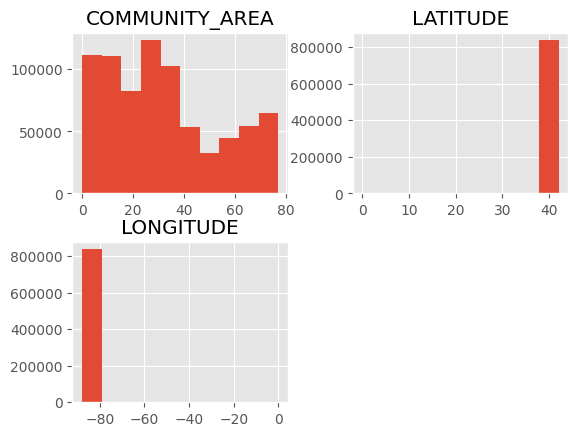

In [138]:
chicago_permits_df_sub.hist()

## Plotting a time series

<Axes: xlabel='APPLICATION_START_DATE'>

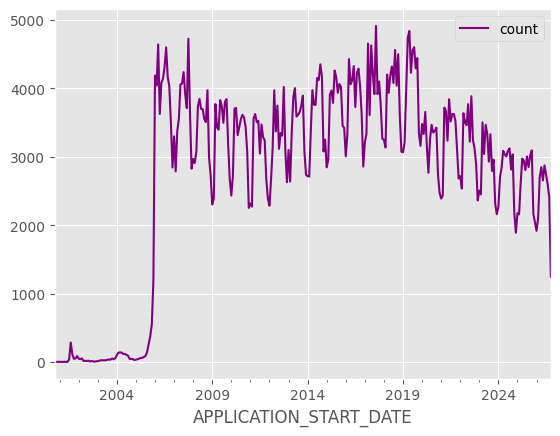

In [139]:
import matplotlib.pyplot as plt
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()
plt.style.use("ggplot")

data_df.plot(color="purple")

Notice how the number of applications in 2005 and before looks suspiciously low. My intuition is that this is a data problem. Let's remove all data from before 2006, since bad data will impact the accuracy of our model. Let's also remove data from before October of this year, since October is incomplete.

<Axes: xlabel='APPLICATION_START_DATE'>

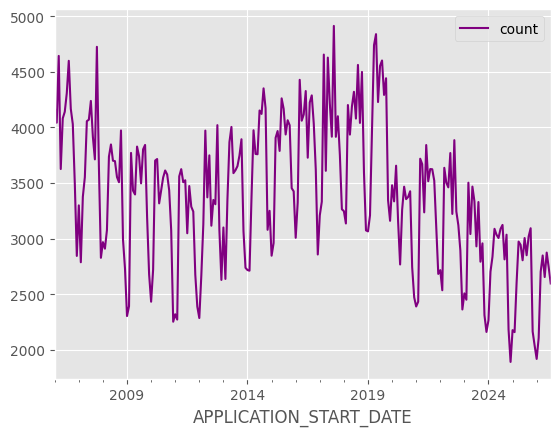

In [140]:
def is_between_2006_and_now(date):
    return date > datetime.datetime(2006, 1, 1) and date < datetime.datetime(2026, 9, 1)
#Please update the date range

data_df = data_df[data_df.index.to_series().apply(is_between_2006_and_now)]
data_df.plot(color="purple")

This plot makes two things pretty clear. First, there are some clear trends in the time series -- for example, an increase between 2011 and 2017, followed by a levelling off of permit applications. Second, there is a cyclic nature to the time series, which is indicative of there being seasonal variation in permit applications (which isn't surprising).

### Q3

Using your own dataset, create two different visualizations to analyze the data, using Python and any plotting library of your choice (e.g., Matplotlib, Seaborn, Plotly). For each dataset, spend some time observing the visualizations, and identify any significant patterns or trends you found. Describe the insights or trends revealed, and discuss how these findings can help address the research question you identified.

array([[<Axes: title={'center': 'A_MEAN'}>,
        <Axes: title={'center': 'A_MEDIAN'}>],
       [<Axes: title={'center': 'A_PCT10'}>,
        <Axes: title={'center': 'A_PCT25'}>],
       [<Axes: title={'center': 'A_PCT75'}>,
        <Axes: title={'center': 'A_PCT90'}>]], dtype=object)

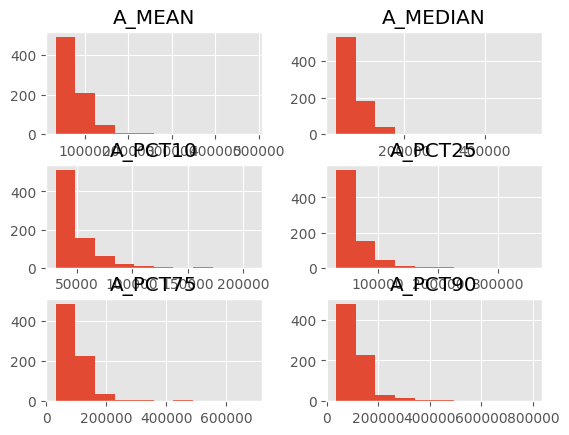

In [149]:
## TODO : Q3

illinois_df[['A_MEAN','A_MEDIAN','A_PCT10', 'A_PCT25', 'A_PCT75', 'A_PCT90']].hist()

<Axes: >

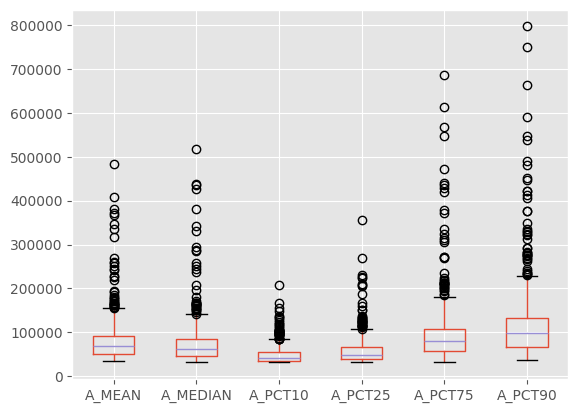

In [ ]:
## TODO : Q3

illinois_df[['A_MEAN','A_MEDIAN','A_PCT10', 'A_PCT25', 'A_PCT75', 'A_PCT90']].boxplot()

"""
This dataset is not a time-series, which eliminates several common types of graphs.
For this reason, I chose a boxplot and histogram, and both of these show a similar pattern
in this case. These charts both show that income is clustered heavily around middle to low
paying jobs, with many extreme high values stretching the distribution upwards. Interestingly,
according to the box plot, this trend exists both across jobs and within jobs. This is shown
by each individual percentile having this high-stretched distribution, and the higher percentiles
have a progressively more increased stretch than lower percentiles

"""